# 20 · Part 2 - Segmentation and load insights (workspace)

Owner: ______  ·  Output: `outputs/part2_segments.csv` (customer_number + segment columns)

Brief examples: high electrification, peak demand contributors, seasonal customers, flexible load, likely adopters, emerging electrification. Plus any insight useful for planning, forecasting, demand response or program design.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from avangrid.config import Paths, PROGRAM_BATTERY, INCREMENTAL_LOAD_LIMIT_KVA, SERVICE_KVA
from avangrid import pipeline, plots, labels, battery, features
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
P = Paths(ROOT)
D = pipeline.load_project(P)          # run 01_data_pipeline.ipynb once first
T = D.table
print(f"{len(T):,} customers | analysis-ready: {T.analysis_ready.sum():,}")
profiles = pd.read_parquet(P.outputs / "seasonal_profiles.parquet")   # season x day type x hour mean kW
daily = pd.read_parquet(P.outputs / "daily_kwh.parquet")              # 365 daily totals
print(profiles.shape, daily.shape)

25,653 customers | analysis-ready: 25,170
(25653, 193) (25653, 366)


## Tools
System peak hours (sum of loaded customers) and per-customer coincidence features are already in the table: `kw_sys_top100`, `kw_sys_top50_winter`, `kw_sys_top50_summer`, `coincidence_factor`, `share_of_sys_top100`.

top-100 system hours by month:
ts
6    16
7    71
8    13


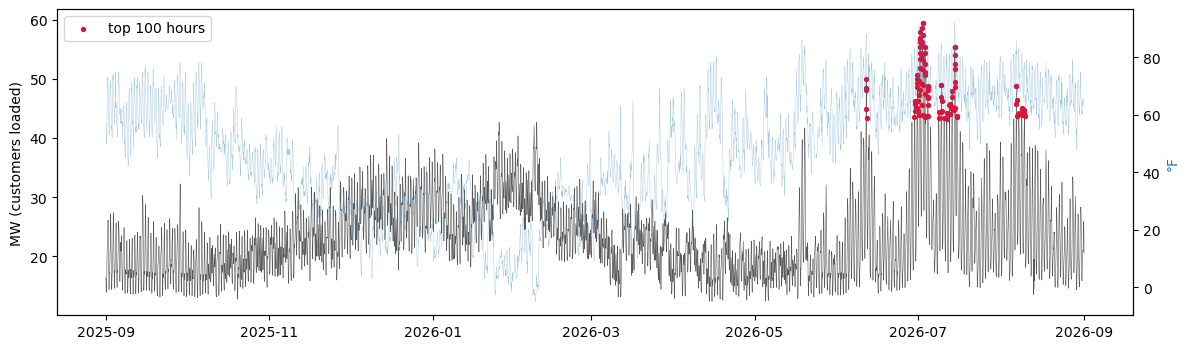

In [2]:
S = D.system
print("top-100 system hours by month:"); print(S.nsmallest(100, "rank").ts.dt.month.value_counts().sort_index().to_string())
plots.system_load_plot(S, D.weather); plt.show()

In [3]:
# Profile matrix ready for clustering (rows = customers, 192 columns = season x day type x hour)
X = profiles.set_index("customer_number")
X = X.loc[T.loc[T.analysis_ready, "customer_number"]]
print(X.shape)
# e.g. shape only: X.div(X.mean(axis=1), axis=0)

(25170, 192)


Once Part 1 exists: `cls = pd.read_csv(P.outputs / 'part1_classification.csv')` and merge on `customer_number`.

## Segment design
**Definition:** 

**Why it matters to the utility:** 

## High electrification
**Definition:** 

**Why it matters to the utility:** 

## Peak demand contributors
**Definition:** 

**Why it matters to the utility:** 

## Seasonal customers
**Definition:** 

**Why it matters to the utility:** 

## Flexible load customers
**Definition:** 

**Why it matters to the utility:** 

## Likely adopters of new technology
**Definition:** 

**Why it matters to the utility:** 

## Emerging electrification candidates
**Definition:** 

**Why it matters to the utility:** 

## Additional insights (planning / forecasting / DR / programs)
**Definition:** 

**Why it matters to the utility:** 

## Export

In [4]:
# seg = T[["customer_number"]].copy(); seg["segment_..."] = ...
# seg.to_csv(P.outputs / "part2_segments.csv", index=False)